# EMA filter golden model

Roadmap block 1 (`dsp01_ema_filter`): single first-order IIR (EMA) stage,
`y[n] = y[n-1] + alpha*(x[n] - y[n-1])`, `alpha = 1 - exp(-Ts/tau)`.

Floating-point model first — validate step response and -3dB bandwidth
against theory (and real MFLI output once available) before touching
fixed-point/bit widths.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

Matplotlib is building the font cache; this may take a moment.


In [2]:
def alpha_from_tau(tau, Ts):
    return 1 - np.exp(-Ts / tau)

def ema_filter(x, alpha):
    y = np.zeros_like(x)
    for n in range(1, len(x)):
        y[n] = y[n - 1] + alpha * (x[n] - y[n - 1])
    return y

## Step response vs. analytic `1 - exp(-t/tau)`

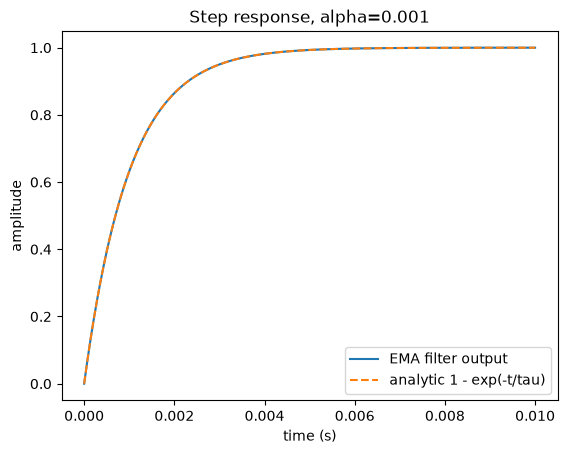

In [3]:
Ts = 1e-6    # placeholder sample period; replace once ADC rate is known
tau = 1e-3   # placeholder time constant

alpha = alpha_from_tau(tau, Ts)

n_samples = int(10 * tau / Ts)
t = np.arange(n_samples) * Ts
x = np.ones(n_samples)
y = ema_filter(x, alpha)

plt.plot(t, y, label='EMA filter output')
plt.plot(t, 1 - np.exp(-t / tau), '--', label='analytic 1 - exp(-t/tau)')
plt.xlabel('time (s)')
plt.ylabel('amplitude')
plt.legend()
plt.title(f'Step response, alpha={alpha:.3g}')
plt.show()

## Frequency response vs. theoretical -3dB point

n=1 (single stage): `f3dB = sqrt(2^(1/1) - 1) / (2*pi*tau) = 1 / (2*pi*tau)`.

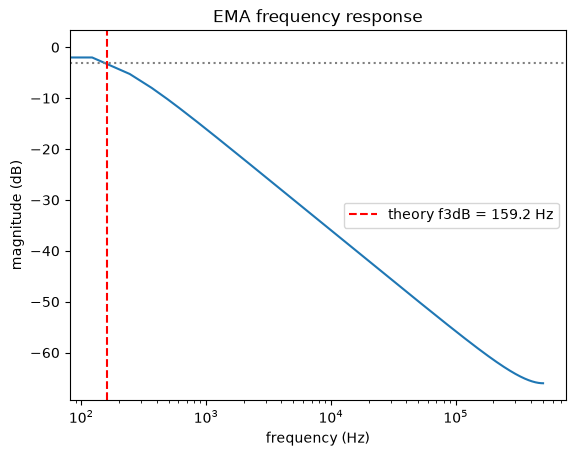

In [4]:
# discrete transfer function: y[n] = (1-alpha) y[n-1] + alpha x[n]
b = [alpha]
a = [1, -(1 - alpha)]
w, h = signal.freqz(b, a, worN=4096, fs=1 / Ts)

f3dB_theory = 1 / (2 * np.pi * tau)

plt.semilogx(w, 20 * np.log10(np.abs(h)))
plt.axvline(f3dB_theory, color='r', linestyle='--', label=f'theory f3dB = {f3dB_theory:.1f} Hz')
plt.axhline(-3, color='gray', linestyle=':')
plt.xlabel('frequency (Hz)')
plt.ylabel('magnitude (dB)')
plt.legend()
plt.title('EMA frequency response')
plt.show()